# Haykin Ch.6 — Scalar AR(1) LMS prediction

保留 300 samples、100 trials、μ=0.01/0.05/0.1，並標示 independence approximation 的理論曲線。

來源：`Haykin-Chap6.ipynb`。所有資料與結果留在記憶體，圖表使用共用深色風格。

執行順序：設定 → 參數與資料 → 模型與訓練 → 圖表與數值摘要。

## 1. Setup

In [ ]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Data and model factories

In [ ]:
from adsp.experiments import haykin

n_samples, n_trials, seed = 300, 100, 30
pole, process_variance = 0.99, 0.936
make_data = partial(data.ar_prediction, n_samples, coefficients=[pole], variance=process_variance)
models = {f"LMS μ={mu}": partial(af.LMS, filter_order=0, mu=mu / 2) for mu in (0.01, 0.05, 0.1)}
results = training.compare(models, make_data, n_trials=n_trials, seed=seed)
noise_floor = process_variance * (1 - pole**2)

## 3. Measured and approximate theoretical learning curves

In [ ]:
fig, grid = plot.axes(rows=2)
plot.learning(results, ax=grid[0, 0], noise_floor=noise_floor, window=9)
theory = {f"Theory μ={mu}": haykin.scalar_lms_theory(n_samples, mu=mu) for mu in (0.01, 0.05, 0.1)}
plot.lines(theory, ax=grid[1, 0], scale="db", ylabel="MSE (dB)", title="Small-step independence approximation")
plot.show(fig)
plot.coefficients(results["LMS μ=0.05"], reference=np.array([pole]))
plot.show()
training.summary(results, noise_floor=noise_floor)

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

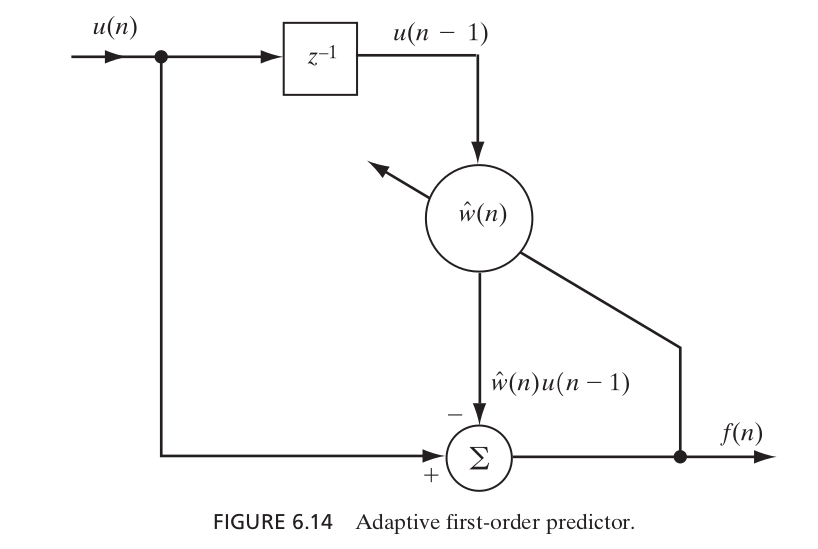

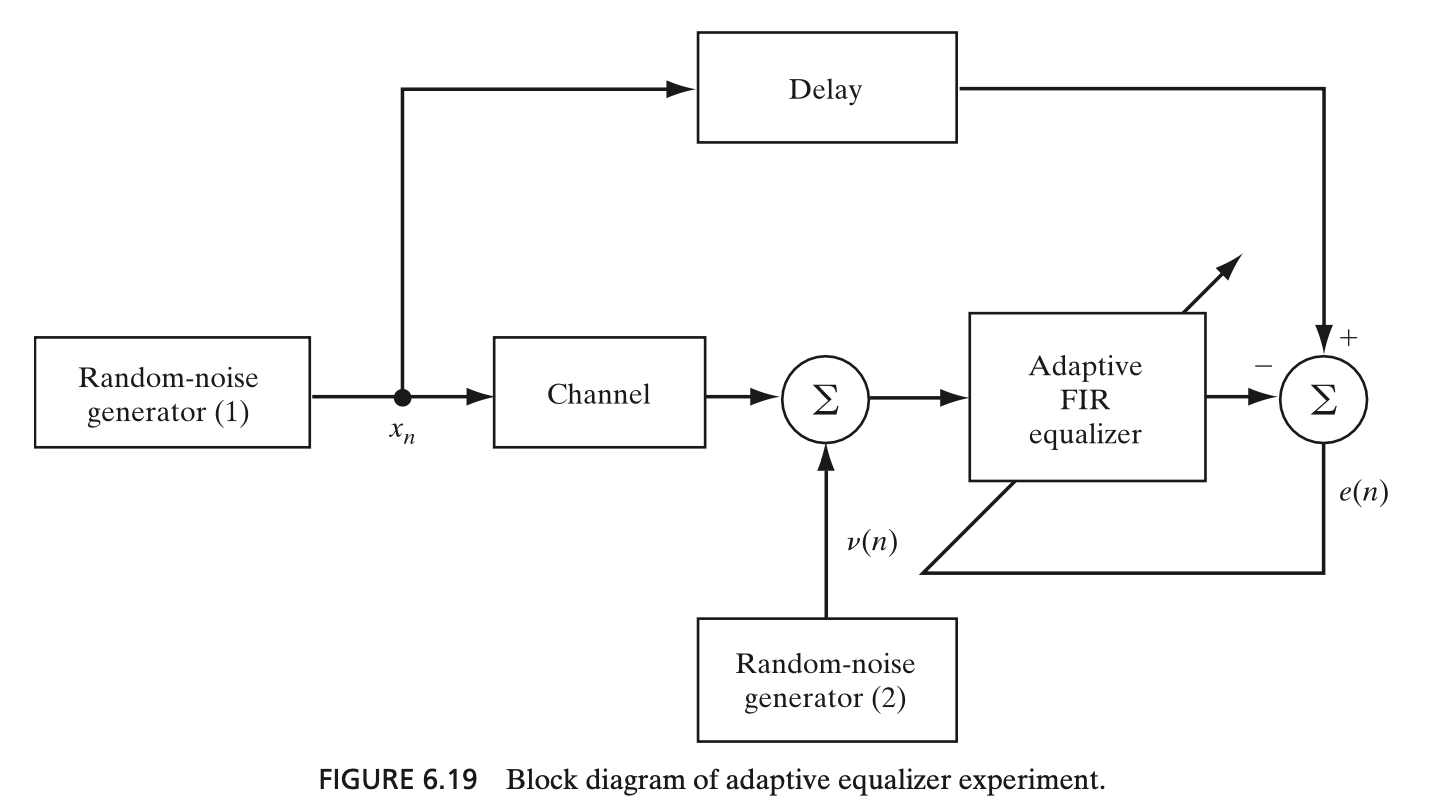